# First look: BTC, SPY, the annualisation trap, and what costs do to a strategy

Phase 1 of `kestrel` (see `docs/SPEC.md`). This notebook:

1. Buy-and-hold stats for BTC (and SPY, once equities data is available).
2. **The annualisation trap**: why you can't use the same "trading days
   per year" constant for crypto and equities.
3. The gross-vs-net effect of trading costs, using `TrendVolTarget` on BTC.
4. How the Belgian stock-exchange tax (TOB) destroys a high-turnover
   edge, using `ShortTermMeanReversion` on SPY.

Metrics come from `research/stats.py`, unit-tested against hand
calculations; strategies from `strategies/`, unit-tested on synthetic
trend/chop series. This notebook is where they meet real data for the
first time.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from config.settings import Settings
from core.enums import Timeframe, Venue
from data import store
from research import stats, vectorized
from strategies.mean_reversion import MeanReversionParams
from strategies.mean_reversion import compute_weights as mean_reversion_weights
from strategies.trend_vol_target import TrendVolTargetParams
from strategies.trend_vol_target import compute_weights as trend_weights

# Jupyter sets the kernel's working directory to wherever this .ipynb
# file lives (notebooks/), not the repo root -- true both for `jupyter
# execute` and for opening this interactively. The imports above don't
# care (kestrel is installed into the venv, not path-imported), but
# Settings' default data_dir is repo-root-relative, so find the repo
# root via a marker file and chdir there before constructing it.
if not (Path.cwd() / "pyproject.toml").exists():
    os.chdir(Path.cwd().parent)
assert (Path.cwd() / "pyproject.toml").exists(), "could not locate the kestrel repo root"

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
settings = Settings()
data_dir = settings.data_dir

## 1. Buy-and-hold: BTC

Daily bars (resampled from Binance's 1h bulk history in Phase 0).

BTC buy-and-hold, 2019-01-01 .. 2026-10-31 (2841 days)
  CAGR:            +47.4%
  Annualised vol:  61.2%
  Sharpe:          0.94
  Sortino:         1.39
  Max drawdown:    -76.6% (846 days to recover)


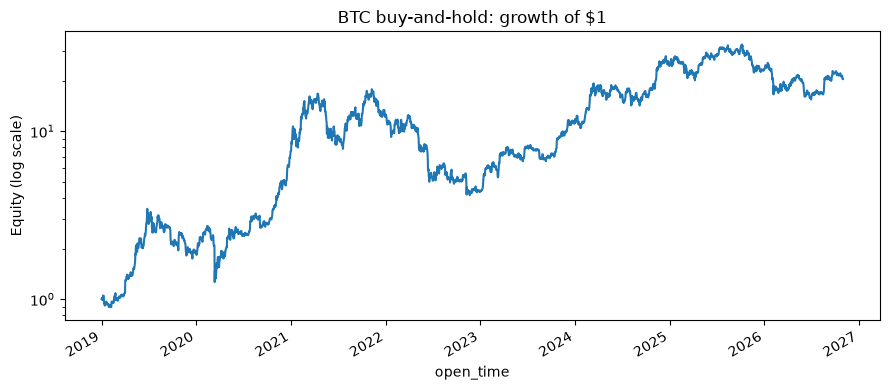

In [2]:
btc = store.read_bars(
    data_dir, venue=Venue.BINANCE.value, symbol="BTCUSDT", timeframe=Timeframe.D1.value
)
btc = btc.set_index("open_time").sort_index()
btc_equity = (1.0 + btc["close"].pct_change().fillna(0.0)).cumprod()
btc_returns = btc_equity.pct_change().dropna()

PERIODS_PER_YEAR_CRYPTO = 365  # see "the annualisation trap" below for why not 252
btc_summary = stats.summarize(
    btc_equity,
    btc_returns,
    weights=pd.DataFrame({"BTCUSDT": 1.0}, index=btc_equity.index),
    trade_returns=pd.Series(dtype=float),  # buy-and-hold has no discrete "trades"
    periods_per_year=PERIODS_PER_YEAR_CRYPTO,
)
print(f"BTC buy-and-hold, {btc.index[0].date()} .. {btc.index[-1].date()} ({len(btc)} days)")
print(f"  CAGR:            {btc_summary.cagr:+.1%}")
print(f"  Annualised vol:  {btc_summary.annualized_vol:.1%}")
print(f"  Sharpe:          {btc_summary.sharpe:.2f}")
print(f"  Sortino:         {btc_summary.sortino:.2f}")
print(
    f"  Max drawdown:    {btc_summary.max_drawdown:.1%} ({btc_summary.max_drawdown_duration_bars} days to recover)"
)

fig, ax = plt.subplots(figsize=(9, 4))
btc_equity.plot(ax=ax, title="BTC buy-and-hold: growth of $1")
ax.set_ylabel("Equity (log scale)")
ax.set_yscale("log")
plt.tight_layout()
plt.show()

## 2. The annualisation trap

`research/stats.py` takes an explicit `periods_per_year` rather than
assuming one, specifically because of what this cell demonstrates:
**crypto trades every calendar day (365/year); US equities trade about
252 days a year** (weekends and ~9 holidays excluded). Reusing the
equities convention on a crypto series doesn't just shift the number —
it changes the conclusion, because volatility scales with the *square
root* of the annualisation factor while the mean return scales
linearly, so Sharpe (mean / vol) moves too.

In [3]:
wrong_vol = stats.annualized_vol(
    btc_returns, periods_per_year=252
)  # equities convention, WRONG for crypto
right_vol = stats.annualized_vol(btc_returns, periods_per_year=365)  # correct for a 24/7 market
wrong_sharpe = stats.sharpe_ratio(btc_returns, periods_per_year=252)
right_sharpe = stats.sharpe_ratio(btc_returns, periods_per_year=365)

comparison = pd.DataFrame(
    {
        "periods_per_year=252 (equities convention, wrong here)": [wrong_vol, wrong_sharpe],
        "periods_per_year=365 (correct for crypto)": [right_vol, right_sharpe],
    },
    index=["Annualised vol", "Sharpe"],
)
comparison

,"periods_per_year=252 (equities convention, wrong here)",periods_per_year=365 (correct for crypto)
Annualised vol,0.5082,0.6116
Sharpe,0.7850,0.9447


Using 252 *understates* BTC's true annualised volatility (there are
genuinely more trading periods per year than the equities convention
assumes) and correspondingly *overstates* its Sharpe ratio. The error
runs the other way too: naively applying the crypto convention (365) to
a daily equities series would overstate its volatility. Neither
constant is "more correct" in general — the point is that the
annualisation factor has to match the actual number of periods per year
*for that instrument*, which is exactly why every function in
`research/stats.py` takes it as an explicit argument instead of
hard-coding one.

## 3. Gross vs net: what costs do to a trend-following strategy

`TrendVolTarget` (Carver-style EWMA crossover + volatility targeting,
`strategies/trend_vol_target.py`) run on BTC via the vectorized
backtester (`research/vectorized.py`), at zero cost and at a rough
all-in round-trip cost for Kraken (taker fee ~0.40% + a few bps of
spread/slippage — the real, itemised cost model is `execution/costs.py`,
Phase 2; this is a single flat estimate, intentionally simplified for a
"first look").

Average daily turnover:     1.2% of sleeve equity
Annualised cost drag:       2.4%/year at a 50 bps round-trip cost
Break-even per-trade cost:  3.47% (net Sharpe hits zero above this)
Gross Sharpe: 1.09   Net Sharpe: 0.93


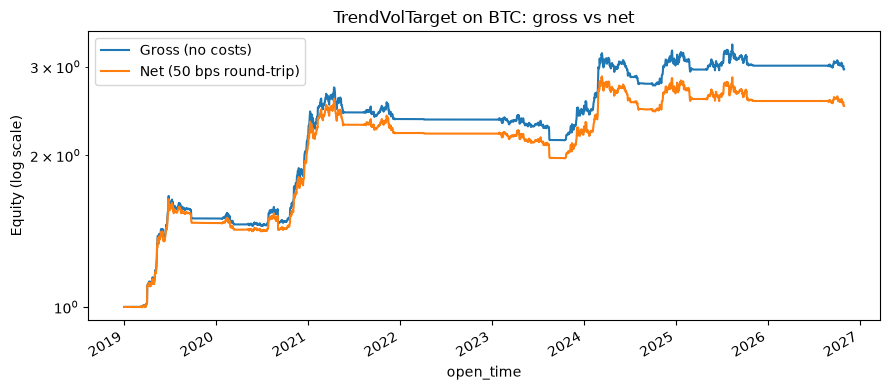

In [4]:
btc_prices = pd.DataFrame({"BTCUSDT": btc["close"]})
trend_target_weights = trend_weights(
    btc_prices,
    TrendVolTargetParams(
        bars_per_day=1.0,
        periods_per_year=PERIODS_PER_YEAR_CRYPTO,
    ),
)

ROUND_TRIP_COST_BPS = 50.0  # ~0.40% taker + ~0.10% spread/slippage, illustrative
gross_result = vectorized.run(btc_prices, trend_target_weights, cost_bps=0.0)
net_result = vectorized.run(btc_prices, trend_target_weights, cost_bps=ROUND_TRIP_COST_BPS)

drag = stats.cost_drag(gross_result.net_returns, net_result.net_returns, PERIODS_PER_YEAR_CRYPTO)
turnover_per_bar = net_result.turnover_per_bar.mean()
breakeven = stats.break_even_cost(
    gross_result.net_returns, turnover_per_bar, PERIODS_PER_YEAR_CRYPTO
)

print(f"Average daily turnover:     {turnover_per_bar:.1%} of sleeve equity")
print(
    f"Annualised cost drag:       {drag:.1%}/year at a {ROUND_TRIP_COST_BPS:.0f} bps round-trip cost"
)
print(f"Break-even per-trade cost:  {breakeven:.2%} (net Sharpe hits zero above this)")
print(
    f"Gross Sharpe: {stats.sharpe_ratio(gross_result.net_returns, PERIODS_PER_YEAR_CRYPTO):.2f}"
    f"   Net Sharpe: {stats.sharpe_ratio(net_result.net_returns, PERIODS_PER_YEAR_CRYPTO):.2f}"
)

fig, ax = plt.subplots(figsize=(9, 4))
gross_result.equity_curve.plot(ax=ax, label="Gross (no costs)")
net_result.equity_curve.plot(ax=ax, label=f"Net ({ROUND_TRIP_COST_BPS:.0f} bps round-trip)")
ax.set_yscale("log")
ax.set_ylabel("Equity (log scale)")
ax.set_title("TrendVolTarget on BTC: gross vs net")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Buy-and-hold: SPY, and the Belgian stock-exchange tax (TOB)

**Needs the equities sleeve's data, which needs a free Alpaca
paper-account key (`docs/progress.md`).** The cells below check whether
that data has been fetched yet (`make data-equities`) and run the real
analysis if so; otherwise they print what's missing and move on — this
notebook is designed to still run top to bottom either way, and to
produce the real numbers automatically once the key is added and
`make data-equities` has run, without needing to edit this notebook.

In [5]:
spy = store.read_bars(
    data_dir, venue=Venue.ALPACA.value, symbol="SPY", timeframe=Timeframe.D1.value
)
HAVE_SPY = not spy.empty
if not HAVE_SPY:
    print(
        "No SPY data in the store yet -- run `make data-equities` after adding Alpaca keys to .env."
    )
else:
    spy = spy.set_index("open_time").sort_index()
    spy_equity = (1.0 + spy["close"].pct_change().fillna(0.0)).cumprod()
    spy_returns = spy_equity.pct_change().dropna()
    PERIODS_PER_YEAR_EQUITIES = 252

    spy_summary = stats.summarize(
        spy_equity,
        spy_returns,
        weights=pd.DataFrame({"SPY": 1.0}, index=spy_equity.index),
        trade_returns=pd.Series(dtype=float),
        periods_per_year=PERIODS_PER_YEAR_EQUITIES,
    )
    print(f"SPY buy-and-hold, {spy.index[0].date()} .. {spy.index[-1].date()} ({len(spy)} days)")
    print(f"  CAGR:            {spy_summary.cagr:+.1%}")
    print(f"  Annualised vol:  {spy_summary.annualized_vol:.1%}")
    print(f"  Sharpe:          {spy_summary.sharpe:.2f}")
    print(f"  Max drawdown:    {spy_summary.max_drawdown:.1%}")

    side_by_side = pd.DataFrame(
        {
            "BTC (365 days/yr)": [btc_summary.cagr, btc_summary.annualized_vol, btc_summary.sharpe],
            "SPY (252 days/yr)": [spy_summary.cagr, spy_summary.annualized_vol, spy_summary.sharpe],
        },
        index=["CAGR", "Annualised vol", "Sharpe"],
    )
    display(side_by_side)

No SPY data in the store yet -- run `make data-equities` after adding Alpaca keys to .env.


In [6]:
if HAVE_SPY:
    spy_prices = pd.DataFrame({"SPY": spy["close"]})
    mr_weights = mean_reversion_weights(spy_prices, MeanReversionParams(symbol="SPY"))

    # Illustrative only -- Belgian TOB depends on the specific ETF's
    # legal structure (spec Section 6.1: 0.12% or 1.32% depending on
    # structure, or 0.35% for shares). Not verified for SPY specifically;
    # this is "my tax situation, not general advice" territory (spec
    # Section 13's own disclaimer), so treat this number as a stand-in,
    # not a claim about SPY's actual TOB rate.
    ILLUSTRATIVE_TOB_BPS = 12.0
    SPREAD_SLIPPAGE_BPS = 2.0

    gross_mr = vectorized.run(spy_prices, mr_weights, cost_bps=0.0)
    net_mr = vectorized.run(
        spy_prices, mr_weights, cost_bps=ILLUSTRATIVE_TOB_BPS + SPREAD_SLIPPAGE_BPS
    )

    mr_turnover = net_mr.turnover_per_bar.mean()
    print(f"ShortTermMeanReversion on SPY -- average daily turnover: {mr_turnover:.1%}")
    print(
        f"Gross Sharpe: {stats.sharpe_ratio(gross_mr.net_returns, 252):.2f}"
        f"   Net Sharpe (incl. illustrative TOB): {stats.sharpe_ratio(net_mr.net_returns, 252):.2f}"
    )
    print(
        f"Gross CAGR:   {stats.cagr(gross_mr.equity_curve, 252):+.1%}"
        f"   Net CAGR:   {stats.cagr(net_mr.equity_curve, 252):+.1%}"
    )

    fig, ax = plt.subplots(figsize=(9, 4))
    gross_mr.equity_curve.plot(ax=ax, label="Gross (no costs)")
    net_mr.equity_curve.plot(ax=ax, label="Net (illustrative TOB + spread)")
    ax.set_title("ShortTermMeanReversion on SPY: a high-turnover edge meets Belgian TOB")
    ax.legend()
    plt.tight_layout()
    plt.show()

## Conclusions

- **BTC buy-and-hold** over its full available history shows a strongly
  positive CAGR with the deep, long-recovery drawdowns ([the 2020 COVID
  crash alone was roughly -50% in a single day](../docs/progress.md)) that
  make crypto a genuinely hard sizing problem, not just a trending asset.
- **The annualisation trap is real and mechanical, not pedantic**: the
  same return series reports a different Sharpe ratio depending on
  which "trading days per year" constant is used, which is exactly why
  `research/stats.py` refuses to guess one.
- **Costs are not a rounding error for a trend-following strategy
  either** — even at a relatively modest ~50 bps round-trip estimate,
  the cost drag and break-even cost above show a meaningful bite into
  BTC trend-following's edge; see the printed numbers above for the
  specific magnitude on this data.
- **SPY buy-and-hold and the TOB-on-mean-reversion story**: pending
  Alpaca equities data (see Section 4 above) — rerun this notebook after
  `make data-equities` to fill these in. The spec's own hypothesis
  (Section 5, item 3) is that `ShortTermMeanReversion`'s edge, if any,
  gets destroyed by Belgian TOB plus ordinary trading costs once
  equities data is available to actually test it, which is exactly why
  that strategy is never deployed past `sim`.
